# Implementation of TMSE-BioCRNpyler Modules: Simplified DNA AND Gate simulation

**Installing and Initializing Modules**: See [README](https://github.com/usnistgov/TMSE_BioCRNpyler_Library/blob/main/README.md) documentation for additional details.

The following sections highlight important features of the TMSE-BioCRNpyler modules.

This notebook illustrate how to compile and simulate a simplified AND gate using the seesaw gate design, from Compiler-aided Systematic Construction of Large-scale DNA Strand Displacement Circuits using Unpurified Components ([Thubagere et al. *Nature Communications* 2017](https://www.nature.com/articles/ncomms14373)), in BioCRNpyler using the TMSE modules. The first code block implements exisiting BioCRNpyler components, mechanisms, and mixtures seemlessly with the TMSE modules to compile a chemcial reaction network (CRN). The CRN is then simulated using BioSCRAPE at various initial conditions in the second code block. 

Specific Features:
* specifying strand exchange molecules from a dictionary directly using `TMSE()`
* generating a strand exchange reactions dictionary using `TMSE()` 

## Global variables, definitions, and dependencies

In [1]:
from biocrnpyler import *
import numpy as np
import pylab as plt
from pathlib import Path

# Get base directory for BioCRNpyler scripts
directory = Path.cwd()
for p in [directory, *directory.parents]:
    if p.name == 'TMSE_BioCRNpyler_Library':
        base_dir = p
        break

# Location of scripts
tmse_mechs = (base_dir / 'mechanisms' / 'ToeholdMediatedStrandExchange.py').as_posix()
tmse_comps = (base_dir / 'components' / 'ToeholdMediatedStrandExchange.py').as_posix()
rna_comp = (base_dir / 'components' / 'RNAassembly.py').as_posix()

# Run scripts
%run {tmse_mechs}
%run {tmse_comps}
%run {rna_comp}

# Directory for Figures and Data
figs_dir = (base_dir / 'figures').as_posix()
data_dir = (base_dir / 'data').as_posix()

In [2]:
# Simulate all models - example for 4 hours
timepoints = np.linspace(0,4,5001)*3600

#Definition to un-nest lists that will be created by models
def flatten(t):
    return [item for sublist in t for item in sublist]

# Set a global default size for plots
plt.rcParams["figure.figsize"] = (7, 7)
font = 'MS Reference Sans Serif'
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams['font.sans-serif'] = ['MS Reference Sans Serif']

# Plotting format
def FormatPlot(ylabel, fig_name, ymin = -0.02, ymax = 100):
    fs = 22
    
    plt.ylabel(ylabel,fontsize=fs)
    plt.xlabel('Time (h)',fontsize=fs)
    plt.legend(title='Input',frameon=False, 
               title_fontsize = fs, fontsize=fs)

    plt.ylim(ymin,ymax)
    plt.xlim(0,4)
    plt.xticks(fontsize=fs)
    plt.yticks(fontsize=fs)
    plt.xticks(np.arange(0, 5, 1))

    # Save plot as svg
    plt.savefig(f'{figs_dir}/main_{fig_name}.svg')

# Simplified DNA AND Gate simulation

![Simplified DNA AND Gate](../schematics/Figure2_DNAgate.png)

**Simplified DNA AND Gate Simulation**

*Note: The leak reaction, Fuel DNA, and Threshold Gate DNA from original reactions have been omitted.*

In [3]:
# Define initial DNA and Reporter RNA
sim_inputs = {'DNA_1': ['Input',1], 'DNA_2': ['Input',3], # Input DNA
              'DNA_3':['Gate',1,2],'DNA_4':['Gate',3,2], 'DNA_5':['Gate',2,4], # Gate DNA
              'DNA_6':['Reporter',4]} # Reporter DNA

# Components
# option 1
step_strands =StrandExchangeMol(sim_inputs, material_type= 'dna')
step_tmse =TMSE(step_strands.mol)

# #option 2
# step_tmse = TMSE(sim_inputs)

# Reactions: strand displacement
mech_sd = OneStepTMSE()
sd_mechanisms = {mech_sd.mechanism_type:mech_sd}

# Parameters
parameters_AND = {"kx":5e4/1e9,
                  "krev":5e4/1e9,
                  "krep":5e4/1e9
                  } 

# Make Mixture and Compile
M_DNAseesaw_AND = Mixture("SeeSaw_AND", 
                          components=[step_tmse],
                          parameters=parameters_AND,
                          mechanisms=sd_mechanisms)

# Compile the CRN with Mixture.compile_crn
CRN_DNAseesaw_AND = M_DNAseesaw_AND.compile_crn()

# Print CRN reactions
print(CRN_DNAseesaw_AND.pretty_print(show_rates = True, how_attributes = True, 
                            show_materials = True, show_keys = False))


Species(N = 15) = {
dna[Signal_4] (@ 0),  dna[Reporter_4] (@ 0),  dna[ReporterOut_4] (@ 0),  dna[Output_3_2] (@ 0),  dna[Output_2_4] (@ 0),  dna[Output_1_2] (@ 0),  dna[Input_3] (@ 0),  dna[Input_1] (@ 0),  dna[Gate_3_2] (@ 0),  dna[Gate_2_4] (@ 0),  dna[Gate_1_2] (@ 0),  dna[GateOut_3_3] (@ 0),  dna[GateOut_3_2] (@ 0),  dna[GateOut_1_2] (@ 0),  dna[GateOut_1_1] (@ 0),  
}

Reactions (5) = [
0. dna[Gate_1_2]+dna[Input_1] <--> dna[Output_1_2]+dna[GateOut_1_1]
 Kf=k_forward * dna_Gate_1_2 * dna_Input_1
 Kr=k_reverse * dna_Output_1_2 * dna_GateOut_1_1
  k_forward=5e-05
  k_reverse=5e-05

1. dna[Gate_3_2]+dna[Input_3] <--> dna[Output_3_2]+dna[GateOut_3_3]
 Kf=k_forward * dna_Gate_3_2 * dna_Input_3
 Kr=k_reverse * dna_Output_3_2 * dna_GateOut_3_3
  k_forward=5e-05
  k_reverse=5e-05

2. dna[Gate_2_4]+dna[Output_1_2] <--> dna[Output_2_4]+dna[GateOut_1_2]
 Kf=k_forward * dna_Gate_2_4 * dna_Output_1_2
 Kr=k_reverse * dna_Output_2_4 * dna_GateOut_1_2
  k_forward=5e-05
  k_reverse=5e-05

3. dna[G

### Simulated using BioSCRAPE

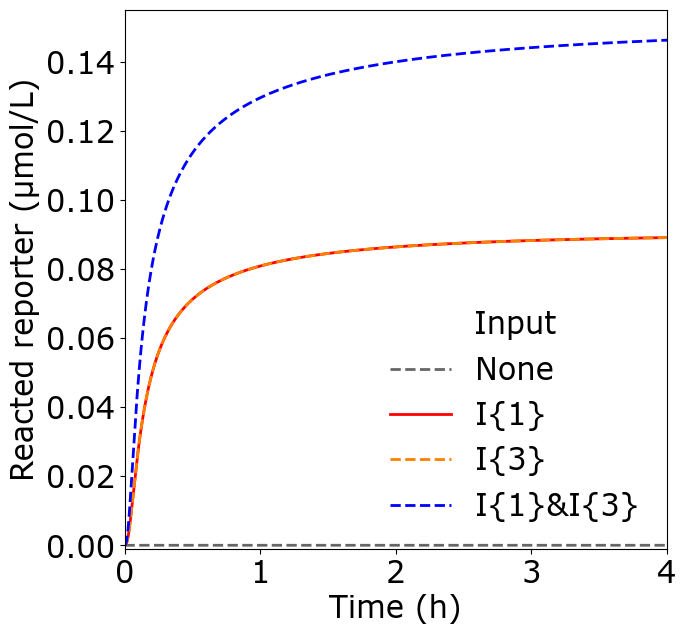

In [4]:
# Simulate
try:
    # Input templates
    IN1 = [0,90,0,90]
    IN3 = [0,0,90,90]

    idx_conditions = {'None':[[0.4,0.4,0.4], '--'],
                      'I{1}': [[1,0,0],'-'],
                      'I{3}': [[1,0.5,0],'--'],
                      'I{1}&I{3}': [[0,0,1],'--']}
    
    for I1_conc, I3_conc, key in zip(IN1, IN3, idx_conditions.keys()):
        # Create an initial condition so A has a non-zero value
        initial_concentration_dict = {'dna_Input_1': I1_conc, 'dna_Input_3': I3_conc,
                                        'dna_Gate_1_2':100, 'dna_Gate_3_2':100, 'dna_Gate_2_4':200,
                                        'dna_Reporter_4':150}
        
        # This function can also take a filename keyword to save the file at the same time
        R = CRN_DNAseesaw_AND.simulate_with_bioscrape_via_sbml(timepoints = timepoints,
                                                                initial_condition_dict = initial_concentration_dict)
        
        # Results are in a Pandas Dictionary and can be accessed via string-names of species
        plt.plot(R['time']/3600, R['dna_Signal_4']/1000, label = key,
                    color = idx_conditions[key][0], linewidth = 2,linestyle = idx_conditions[key][1])
    
except ModuleNotFoundError:
    print("Plotting Modules not installed.")

FormatPlot(ylabel='Reacted reporter (μmol/L)',ymin = -0.001, ymax = 0.155, fig_name= 'Figure2_DNAgate')    


# Computing environment

In [5]:
%load_ext watermark
%watermark -v -p bioscrape,bokeh,jupyterlab,biocrnpyler

Python implementation: CPython
Python version       : 3.12.12
IPython version      : 9.12.0

bioscrape  : 1.2.1
bokeh      : 3.9.1
jupyterlab : 4.5.0
biocrnpyler: 1.3.2

